In [2]:
from pathlib import Path

DATA_DIR = Path("..") / "data"

for f in DATA_DIR.rglob("*"):
    if f.is_file():
        print(f.name, round(f.stat().st_size / 1024**3, 2), "GB")

digikala-comments.csv 1.19 GB
digikala-products.csv 0.24 GB


In [3]:
import duckdb

con = duckdb.connect()
COMMENTS = "../data/digikala-comments.csv"

In [4]:
con.sql(f"""
    DESCRIBE
    SELECT * FROM read_csv('{COMMENTS}', all_varchar=true)
""").show()

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id                    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ title                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ body                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ created_at            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rate                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ recommendation_status │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_buyer              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ product_id            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ advantages            │ VARCHAR     │ 

In [5]:
n_rows = con.sql(f"""
    SELECT COUNT(*) FROM read_csv('{COMMENTS}', all_varchar=true)
""").fetchall()[0][0]

print(f"{n_rows:,}")

6,156,289


In [11]:
con.sql(f"""
    SELECT
        COUNT(*)                    AS n_rows,
        COUNT(DISTINCT id)          AS unique_ids,
        COUNT(DISTINCT product_id)  AS unique_products,
        COUNT(DISTINCT seller_code) AS unique_sellers
    FROM read_csv('{COMMENTS}', all_varchar=true)
""").show()

┌─────────┬────────────┬─────────────────┬────────────────┐
│ n_rows  │ unique_ids │ unique_products │ unique_sellers │
│  int64  │   int64    │      int64      │     int64      │
├─────────┼────────────┼─────────────────┼────────────────┤
│ 6156289 │    6153060 │          331599 │          29214 │
└─────────┴────────────┴─────────────────┴────────────────┘



In [7]:
con.sql(f"""
    SELECT
        COUNT(*) FILTER (WHERE id IS NULL)     AS null_ids,
        COUNT(*) FILTER (WHERE id IS NOT NULL) AS non_null_ids,
        COUNT(DISTINCT id)                     AS unique_ids
    FROM read_csv('{COMMENTS}', all_varchar=true)
""").show()

┌──────────┬──────────────┬────────────┐
│ null_ids │ non_null_ids │ unique_ids │
│  int64   │    int64     │   int64    │
├──────────┼──────────────┼────────────┤
│        0 │      6156289 │    6153060 │
└──────────┴──────────────┴────────────┘



In [8]:
con.sql(f"""
    WITH per_product AS (
        SELECT product_id, COUNT(*) AS n_reviews
        FROM read_csv('{COMMENTS}', all_varchar=true)
        WHERE product_id IS NOT NULL
        GROUP BY product_id
    )
    SELECT
        COUNT(*)                       AS n_products,
        MIN(n_reviews)                 AS min_reviews,
        quantile_cont(n_reviews, 0.5)  AS median_reviews,
        AVG(n_reviews)                 AS mean_reviews,
        quantile_cont(n_reviews, 0.99) AS p99_reviews,
        MAX(n_reviews)                 AS max_reviews
    FROM per_product
""").show()

┌────────────┬─────────────┬────────────────┬────────────────────┬─────────────┬─────────────┐
│ n_products │ min_reviews │ median_reviews │    mean_reviews    │ p99_reviews │ max_reviews │
│   int64    │    int64    │     double     │       double       │   double    │    int64    │
├────────────┼─────────────┼────────────────┼────────────────────┼─────────────┼─────────────┤
│     331599 │           1 │            4.0 │ 18.565463104532885 │       200.0 │         400 │
└────────────┴─────────────┴────────────────┴────────────────────┴─────────────┴─────────────┘



## A1 Findings

- The comments file has 6,156,289 records and 15 columns (1.19 GB), counted with a CSV parser.
- No record has a missing id, but there are only 6,153,060 distinct ids, so 3,229 records reuse an id seen earlier (to be investigated).
- The data covers 331,599 distinct products and 29,214 distinct seller codes.
- Reviews per product are highly skewed: min 1, median 4, mean 18.6, 99th percentile 200, max 400.
- Implication: the largest product holds under 0.01% of all records, so a product-grouped split can reach the 70/15/15 target closely.

In [9]:
con.sql(f"""
    CREATE OR REPLACE TEMP VIEW comments AS
    SELECT * FROM read_csv('{COMMENTS}', all_varchar=true)
""")

CountBIGINT


In [10]:
con.sql("""
    CREATE OR REPLACE TEMP TABLE dup_rows AS
    SELECT * FROM comments
    WHERE id IN (
        SELECT id FROM comments GROUP BY id HAVING COUNT(*) > 1
    )
""")

CountBIGINT
6455


In [11]:
con.sql("""
    SELECT
        CASE WHEN n_versions = 1 THEN 'identical copies'
             ELSE 'same id, different content' END AS kind,
        COUNT(*)    AS n_ids,
        SUM(n_rows) AS n_rows
    FROM (
        SELECT id,
               COUNT(*) AS n_rows,
               COUNT(DISTINCT md5(concat_ws('|', title, body, created_at, rate,
                    recommendation_status, product_id, seller_code))) AS n_versions
        FROM dup_rows
        GROUP BY id
    )
    GROUP BY kind
""").show()

┌────────────────────────────┬───────┬────────┐
│            kind            │ n_ids │ n_rows │
│          varchar           │ int64 │ int128 │
├────────────────────────────┼───────┼────────┤
│ same id, different content │   387 │    774 │
│ identical copies           │  2839 │   5681 │
└────────────────────────────┴───────┴────────┘



In [12]:
con.sql("""
    SELECT id, product_id, rate, left(body, 60) AS body_start
    FROM dup_rows
    ORDER BY id
    LIMIT 10
""").show()

┌──────────┬────────────┬─────────┬──────────────────────────────────────────────────────────────┐
│    id    │ product_id │  rate   │                          body_start                          │
│ varchar  │  varchar   │ varchar │                           varchar                            │
├──────────┼────────────┼─────────┼──────────────────────────────────────────────────────────────┤
│ 10021106 │ 252058     │ 0.0     │ متن روان و گویندگی با صدای دلنشین و بسیار اموزنده            │
│ 10021106 │ 252058     │ 0.0     │ متن روان و گویندگی با صدای دلنشین و بسیار اموزنده            │
│ 1002211  │ 65742      │ 3.0     │ یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکنم حتما گوش بدی │
│ 1002211  │ 65742      │ 3.0     │ یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکنم حتما گوش بدی │
│ 10051223 │ 252058     │ 3.0     │ افزایش سطح اگاهی وبه عنوان هدیه مناسب می باشد.ممنون          │
│ 10051223 │ 252058     │ 3.0     │ افزایش سطح اگاهی وبه عنوان هدیه مناسب می باشد.ممنون          │
│ 10115646

In [13]:
con.sql("""
    WITH per_product AS (
        SELECT product_id, COUNT(*) AS n_reviews
        FROM comments
        WHERE product_id IS NOT NULL
        GROUP BY product_id
    )
    SELECT n_reviews, COUNT(*) AS n_products
    FROM per_product
    WHERE n_reviews IN (198, 199, 200, 201, 202, 398, 399, 400)
    GROUP BY n_reviews
    ORDER BY n_reviews
""").show()

┌───────────┬────────────┐
│ n_reviews │ n_products │
│   int64   │   int64    │
├───────────┼────────────┤
│       198 │         34 │
│       199 │         47 │
│       200 │       8400 │
│       201 │        542 │
│       202 │        297 │
│       400 │          3 │
└───────────┴────────────┘



In [14]:
cols = [r[0] for r in con.sql("DESCRIBE comments").fetchall()]

parts = [
    f"COUNT(*) FILTER (WHERE \"{c}\" IS NULL OR trim(\"{c}\") = '') AS \"{c}\""
    for c in cols
]

miss = con.sql(
    "SELECT COUNT(*) AS total_rows, " + ", ".join(parts) + " FROM comments"
).df()

t = miss.T
t.columns = ["missing"]
total = int(t.loc["total_rows", "missing"])
t = t.drop("total_rows")
t["missing_pct"] = (t["missing"] / total * 100).round(2)
t.sort_values("missing_pct", ascending=False)

,missing,missing_pct
title,1353,0.02
id,0,0.00
body,0,0.00
created_at,0,0.00
rate,0,0.00
recommendation_status,0,0.00
is_buyer,0,0.00
product_id,0,0.00
advantages,0,0.00
disadvantages,0,0.00


In [15]:
con.sql("""
    SELECT recommendation_status, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM comments
    GROUP BY recommendation_status
    ORDER BY n DESC
""").show()

┌───────────────────────┬─────────┬────────┐
│ recommendation_status │    n    │  pct   │
│        varchar        │  int64  │ double │
├───────────────────────┼─────────┼────────┤
│ recommended           │ 4162839 │  67.62 │
│ nan                   │  894426 │  14.53 │
│ no_idea               │  594121 │   9.65 │
│ not_recommended       │  504903 │    8.2 │
└───────────────────────┴─────────┴────────┘



In [16]:
con.sql("""
    SELECT is_buyer, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) FILTER (WHERE recommendation_status IS NULL)
                 / COUNT(*), 2) AS pct_missing_label
    FROM comments
    GROUP BY is_buyer
    ORDER BY n DESC
""").show()

┌──────────┬─────────┬───────────────────┐
│ is_buyer │    n    │ pct_missing_label │
│ varchar  │  int64  │      double       │
├──────────┼─────────┼───────────────────┤
│ True     │ 5854108 │               0.0 │
│ False    │  302181 │               0.0 │
└──────────┴─────────┴───────────────────┘



In [17]:
con.sql("""
    SELECT rate, COUNT(*) AS n
    FROM comments
    GROUP BY rate
    ORDER BY n DESC
    LIMIT 20
""").show()

┌─────────┬─────────┐
│  rate   │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ 5.0     │ 2398801 │
│ 4.0     │ 1515723 │
│ 3.0     │  958799 │
│ 0.0     │  529098 │
│ 1.0     │  327662 │
│ 2.0     │  198077 │
│ 4.5     │   13479 │
│ 3.5     │   12207 │
│ 4.25    │   11653 │
│ 3.75    │   10045 │
│ 4.2     │    9843 │
│ 3.8     │    8745 │
│ 4.4     │    8675 │
│ 4.75    │    8292 │
│ 4.6     │    8152 │
│ 3.25    │    7695 │
│ 4.8     │    7276 │
│ 3.4     │    7250 │
│ 3.6     │    6975 │
│ 2.5     │    5438 │
└─────────┴─────────┘
       20 rows     



In [18]:
for c in ["title", "advantages", "disadvantages", "likes", "dislikes",
          "seller_title", "true_to_size_rate"]:
    print(c)
    con.sql(f"""
        SELECT left("{c}", 40) AS value, COUNT(*) AS n
        FROM comments
        GROUP BY "{c}"
        ORDER BY n DESC
        LIMIT 5
    """).show()

title
┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ nan     │ 2865062 │
│ عالی    │  237796 │
│ خوبه    │  136131 │
│ خوب     │  118195 │
│ خوب بود │   67066 │
└─────────┴─────────┘

advantages
┌────────────────┬─────────┐
│     value      │    n    │
│    varchar     │  int64  │
├────────────────┼─────────┤
│ nan            │ 5448084 │
│ ['عالی']       │   10907 │
│ ['قیمت مناسب'] │    9146 │
│ ['ندارد']      │    8489 │
│ ['کیفیت خوب']  │    6601 │
└────────────────┴─────────┘

disadvantages
┌───────────┬─────────┐
│   value   │    n    │
│  varchar  │  int64  │
├───────────┼─────────┤
│ nan       │ 5744017 │
│ ['ندارد'] │   63177 │
│ ['نداره'] │   15982 │
│ ['ندیدم'] │    6544 │
│ ['هیچی']  │    6348 │
└───────────┴─────────┘

likes
┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ 0       │ 4961822 │
│ 1       │  736634 │
│ 2       │  210218 │
│ 3       │   89701 │
│ 4       │   46841 │
└─────────┴─

In [19]:
con.sql("""
    SELECT
        COUNT(*) AS total,
        COUNT(*) FILTER (WHERE TRY_CAST(rate AS DOUBLE) IS NULL) AS unparseable,
        COUNT(*) FILTER (WHERE TRY_CAST(rate AS DOUBLE) < 0
                            OR TRY_CAST(rate AS DOUBLE) > 5)    AS out_of_range,
        COUNT(*) FILTER (WHERE TRY_CAST(rate AS DOUBLE) = 0)    AS exactly_zero,
        COUNT(*) FILTER (WHERE TRY_CAST(rate AS DOUBLE) % 1 <> 0) AS fractional
    FROM comments
""").show()

┌─────────┬─────────────┬──────────────┬──────────────┬────────────┐
│  total  │ unparseable │ out_of_range │ exactly_zero │ fractional │
│  int64  │    int64    │    int64     │    int64     │   int64    │
├─────────┼─────────────┼──────────────┼──────────────┼────────────┤
│ 6156289 │           0 │            1 │       529098 │     228128 │
└─────────┴─────────────┴──────────────┴──────────────┴────────────┘



In [20]:
con.sql("""
    SELECT TRY_CAST(rate AS DOUBLE) = 0 AS rate_is_zero,
           recommendation_status,
           COUNT(*) AS n
    FROM comments
    GROUP BY ALL
    ORDER BY rate_is_zero, n DESC
""").show()

┌──────────────┬───────────────────────┬─────────┐
│ rate_is_zero │ recommendation_status │    n    │
│   boolean    │        varchar        │  int64  │
├──────────────┼───────────────────────┼─────────┤
│ false        │ recommended           │ 3737094 │
│ false        │ nan                   │  869067 │
│ false        │ no_idea               │  573551 │
│ false        │ not_recommended       │  447479 │
│ true         │ recommended           │  425745 │
│ true         │ not_recommended       │   57424 │
│ true         │ nan                   │   25359 │
│ true         │ no_idea               │   20570 │
└──────────────┴───────────────────────┴─────────┘



In [21]:
con.sql("""
    SELECT recommendation_status = 'nan' AS label_is_missing,
           is_buyer,
           COUNT(*) AS n
    FROM comments
    GROUP BY ALL
    ORDER BY is_buyer, label_is_missing
""").show()

┌──────────────────┬──────────┬─────────┐
│ label_is_missing │ is_buyer │    n    │
│     boolean      │ varchar  │  int64  │
├──────────────────┼──────────┼─────────┤
│ true             │ False    │  302181 │
│ false            │ True     │ 5261863 │
│ true             │ True     │  592245 │
└──────────────────┴──────────┴─────────┘



In [22]:
con.sql("""
    WITH conflicting AS (
        SELECT id FROM dup_rows GROUP BY id
        HAVING COUNT(DISTINCT md5(concat_ws('|', title, body, created_at, rate,
               recommendation_status, product_id, seller_code))) > 1
    )
    SELECT id, product_id, rate, recommendation_status, left(body, 40) AS body_start
    FROM dup_rows
    WHERE id IN (SELECT id FROM conflicting)
    ORDER BY id
    LIMIT 12
""").show()

┌──────────┬────────────┬─────────┬───────────────────────┬────────────────────────────────────────────┐
│    id    │ product_id │  rate   │ recommendation_status │                 body_start                 │
│ varchar  │  varchar   │ varchar │        varchar        │                  varchar                   │
├──────────┼────────────┼─────────┼───────────────────────┼────────────────────────────────────────────┤
│ 12862914 │ 2670905    │ 0.0     │ recommended           │ کرم خوبیه\r\nپیشنهاد میکنم                 │
│ 12862914 │ 2670905    │ 5.0     │ recommended           │ کرم خوبیه\r\nپیشنهاد میکنم                 │
│ 17111330 │ 2952419    │ 1.0     │ not_recommended       │ حتی تو تخفیف هم ارزش خریدن نداره           │
│ 17111330 │ 2952419    │ 0.0     │ not_recommended       │ حتی تو تخفیف هم ارزش خریدن نداره           │
│ 22662971 │ 853680     │ 0.0     │ recommended           │ خوب بود                                    │
│ 22662971 │ 853680     │ 5.0     │ recommended        

In [23]:
con.sql("""
    SELECT id, product_id, rate, recommendation_status, left(body, 60) AS body_start
    FROM comments
    WHERE TRY_CAST(rate AS DOUBLE) < 0 OR TRY_CAST(rate AS DOUBLE) > 5
""").show()

┌──────────┬────────────┬─────────┬───────────────────────┬─────────────────┐
│    id    │ product_id │  rate   │ recommendation_status │   body_start    │
│ varchar  │  varchar   │ varchar │        varchar        │     varchar     │
├──────────┼────────────┼─────────┼───────────────────────┼─────────────────┤
│ 38631814 │ 5095301    │ 2500.0  │ recommended           │ کوچک و با کیفیت │
└──────────┴────────────┴─────────┴───────────────────────┴─────────────────┘



In [24]:
con.sql("""
    SELECT is_buyer, seller_title = 'nan' AS seller_missing, COUNT(*) AS n
    FROM comments
    GROUP BY ALL
    ORDER BY is_buyer, seller_missing
""").show()

┌──────────┬────────────────┬─────────┐
│ is_buyer │ seller_missing │    n    │
│ varchar  │    boolean     │  int64  │
├──────────┼────────────────┼─────────┤
│ False    │ true           │  302181 │
│ True     │ false          │ 5854108 │
└──────────┴────────────────┴─────────┘



In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

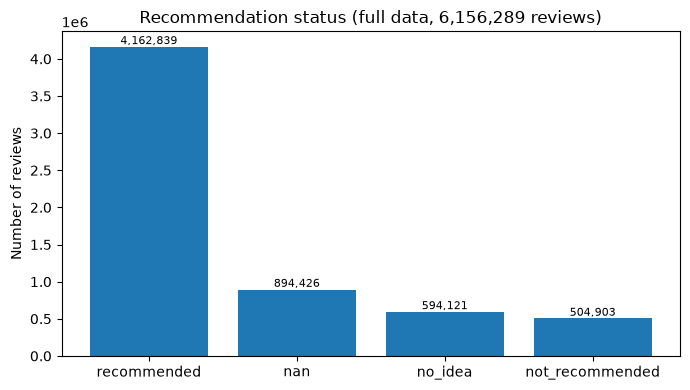

In [26]:
rec = con.sql("""
    SELECT recommendation_status AS label, COUNT(*) AS n
    FROM comments
    GROUP BY label
    ORDER BY n DESC
""").df()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rec["label"], rec["n"])
ax.set_title("Recommendation status (full data, 6,156,289 reviews)")
ax.set_ylabel("Number of reviews")
for i, v in enumerate(rec["n"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_recommendation_distribution.png", dpi=150)
plt.show()

rows left out of the plot: 1


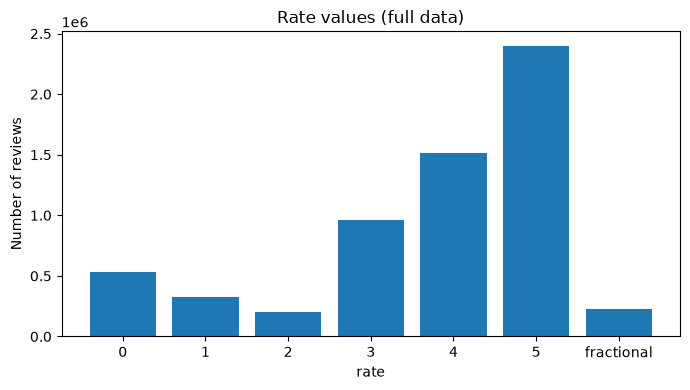

In [27]:
rate_df = con.sql("""
    SELECT CASE WHEN TRY_CAST(rate AS DOUBLE) % 1 = 0
                THEN CAST(CAST(TRY_CAST(rate AS DOUBLE) AS INTEGER) AS VARCHAR)
                ELSE 'fractional' END AS rate_value,
           COUNT(*) AS n
    FROM comments
    GROUP BY rate_value
""").df()

order = ["0", "1", "2", "3", "4", "5", "fractional"]
shown = (rate_df[rate_df["rate_value"].isin(order)]
         .set_index("rate_value").reindex(order).fillna(0))
print("rows left out of the plot:", int(rate_df["n"].sum() - shown["n"].sum()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(shown.index, shown["n"])
ax.set_title("Rate values (full data)")
ax.set_xlabel("rate")
ax.set_ylabel("Number of reviews")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_rate_distribution.png", dpi=150)
plt.show()

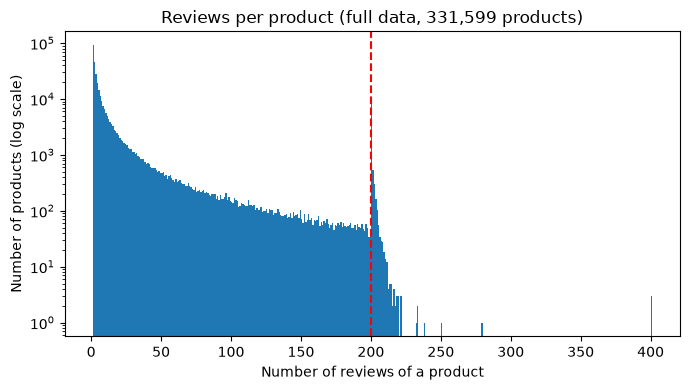

In [28]:
per_prod = con.sql("""
    SELECT product_id, COUNT(*) AS n_reviews
    FROM comments
    WHERE product_id IS NOT NULL
    GROUP BY product_id
""").df()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(per_prod["n_reviews"], bins=range(1, 402), log=True)
ax.axvline(200, color="red", linestyle="--")
ax.set_title("Reviews per product (full data, 331,599 products)")
ax.set_xlabel("Number of reviews of a product")
ax.set_ylabel("Number of products (log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_reviews_per_product.png", dpi=150)
plt.show()

In [29]:
con.sql("""
    SELECT MIN(length(body))                   AS min_len,
           quantile_cont(length(body), 0.5)    AS median_len,
           AVG(length(body))                   AS mean_len,
           quantile_cont(length(body), 0.9)    AS p90_len,
           quantile_cont(length(body), 0.99)   AS p99_len,
           MAX(length(body))                   AS max_len
    FROM comments
""").show()

┌─────────┬────────────┬───────────────────┬─────────┬─────────┬─────────┐
│ min_len │ median_len │     mean_len      │ p90_len │ p99_len │ max_len │
│  int64  │   double   │      double       │ double  │ double  │  int64  │
├─────────┼────────────┼───────────────────┼─────────┼─────────┼─────────┤
│       1 │       29.0 │ 48.39365403411048 │   106.0 │   297.0 │    4000 │
└─────────┴────────────┴───────────────────┴─────────┴─────────┴─────────┘



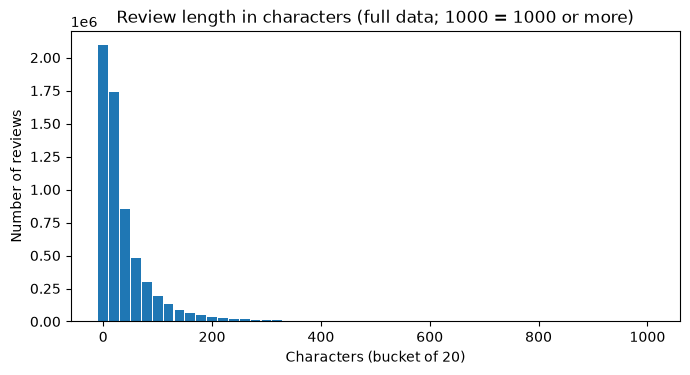

In [30]:
len_df = con.sql("""
    SELECT LEAST(length(body), 1000) // 20 * 20 AS bucket, COUNT(*) AS n
    FROM comments
    GROUP BY bucket
    ORDER BY bucket
""").df()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(len_df["bucket"], len_df["n"], width=18)
ax.set_title("Review length in characters (full data; 1000 = 1000 or more)")
ax.set_xlabel("Characters (bucket of 20)")
ax.set_ylabel("Number of reviews")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_text_length.png", dpi=150)
plt.show()

## A2 Findings: ratings and sellers

- `rate = 0.0` occurs in 529,098 rows. Evidence: 80.5% of these rows are "recommended" (66.4% elsewhere), and one duplicated review has 0.0 in one version and 5.0 in the other. The instructor confirmed that 0 is a placeholder for a missing rating, not a quality score. Decision: the rating scale is 1 to 5; rows with 0 are excluded from the rating-band task only and kept for the recommendation task.
- One row has an invalid rate of 2500.0 (id 38631814); it is excluded from the rating-band task.
- `seller_title` is missing ("nan") exactly for the 302,181 non-buyers (is_buyer = False).
- Review length (characters): min 1, median 29, mean 48.4, p90 106, p99 297, max 4000.

In [32]:
con.sql("""
    SELECT CASE
             WHEN TRY_CAST(rate AS DOUBLE) IS NULL THEN 'unparseable'
             WHEN TRY_CAST(rate AS DOUBLE) = 0 THEN 'zero (treated as no rating)'
             WHEN TRY_CAST(rate AS DOUBLE) > 0
              AND TRY_CAST(rate AS DOUBLE) < 1 THEN 'between 0 and 1'
             WHEN TRY_CAST(rate AS DOUBLE) BETWEEN 1 AND 5 THEN 'valid 1 to 5'
             ELSE 'above 5' END AS rate_group,
           COUNT(*) AS n
    FROM comments
    GROUP BY rate_group
    ORDER BY n DESC
""").show()

┌─────────────────────────────┬─────────┐
│         rate_group          │    n    │
│           varchar           │  int64  │
├─────────────────────────────┼─────────┤
│ valid 1 to 5                │ 5622045 │
│ zero (treated as no rating) │  529098 │
│ between 0 and 1             │    5145 │
│ above 5                     │       1 │
└─────────────────────────────┴─────────┘



In [33]:
con.sql("""
    SELECT COUNT(*) FILTER (WHERE length(body) = 4000) AS len_exactly_4000,
           COUNT(*) FILTER (WHERE length(body) >= 3900) AS len_3900_or_more,
           COUNT(*) FILTER (WHERE length(body) <= 3)    AS len_3_or_less
    FROM comments
""").show()

┌──────────────────┬──────────────────┬───────────────┐
│ len_exactly_4000 │ len_3900_or_more │ len_3_or_less │
│      int64       │      int64       │     int64     │
├──────────────────┼──────────────────┼───────────────┤
│               10 │               13 │         67589 │
└──────────────────┴──────────────────┴───────────────┘



In [34]:
con.sql("""
    SELECT left(body, 40) AS body_start, COUNT(*) AS n
    FROM comments
    GROUP BY body
    ORDER BY n DESC
    LIMIT 10
""").show()

┌───────────────┬────────┐
│  body_start   │   n    │
│    varchar    │ int64  │
├───────────────┼────────┤
│ عالی          │ 121349 │
│ خوب بود       │  73854 │
│ خوبه          │  72210 │
│ خوب           │  64297 │
│ عالی بود      │  23598 │
│ عالیه         │  19719 │
│ معمولی        │  13185 │
│ خیلی خوب بود  │  13130 │
│ خوب بود       │  12014 │
│ پیشنهاد میکنم │  11165 │
└───────────────┴────────┘
  10 rows      2 columns



In [35]:
con.sql("""
    WITH b AS (SELECT body, COUNT(*) AS n FROM comments GROUP BY body)
    SELECT COUNT(*) AS distinct_bodies,
           COUNT(*) FILTER (WHERE n > 1) AS bodies_repeated,
           SUM(n) FILTER (WHERE n > 1)   AS rows_in_repeated_bodies
    FROM b
""").show()

┌─────────────────┬─────────────────┬─────────────────────────┐
│ distinct_bodies │ bodies_repeated │ rows_in_repeated_bodies │
│      int64      │      int64      │         int128          │
├─────────────────┼─────────────────┼─────────────────────────┤
│         4136258 │          197745 │                 2217776 │
└─────────────────┴─────────────────┴─────────────────────────┘



In [36]:
con.sql("""
    WITH t AS (
        SELECT body,
               COUNT(DISTINCT recommendation_status) AS n_labels,
               COUNT(*) AS n
        FROM comments
        WHERE recommendation_status <> 'nan'
        GROUP BY body
        HAVING COUNT(*) > 1
    )
    SELECT COUNT(*) AS repeated_labelled_bodies,
           COUNT(*) FILTER (WHERE n_labels > 1) AS with_conflicting_labels
    FROM t
""").show()

┌──────────────────────────┬─────────────────────────┐
│ repeated_labelled_bodies │ with_conflicting_labels │
│          int64           │          int64          │
├──────────────────────────┼─────────────────────────┤
│                   173905 │                   31942 │
└──────────────────────────┴─────────────────────────┘

